In [1]:
# ============================================
# Smart Manufacturing Digital Twin
# Phase 2: Machine Learning Pipeline
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    # Classification
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,

    # Regression
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = "../data/raw/all_machines_combined.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Dataset loaded successfully!
Rows: 1930
Columns: 17


,Machine_ID,Machine_Type,Failure_Mode,Cycle,Temperature_C,Vibration_mm_s,Pressure_bar,Rotational_Speed_RPM,Load_Fraction,Torque_Nm,Current_A,Acoustic_dB,Wear_Level,Health_Index,Anomaly_Score,Failure,RUL_Cycles
0,CNC_001,CNC_Mill,Bearing,1,68.987,0.2351,2.117,1518.64,0.6513,46.734,9.213,56.022,0.0000,100.000,0.1342,0,259
1,CNC_001,CNC_Mill,Bearing,2,69.431,0.1894,2.126,1517.67,0.5961,46.603,9.480,55.789,0.0000,99.961,0.2990,0,258
2,CNC_001,CNC_Mill,Bearing,3,68.779,0.2385,2.119,1520.83,0.6336,46.313,9.612,54.954,0.0022,99.760,0.2269,0,257
3,CNC_001,CNC_Mill,Bearing,4,68.926,0.2047,2.110,1531.69,0.6898,48.403,9.907,54.567,0.0000,99.884,0.0469,0,256
4,CNC_001,CNC_Mill,Bearing,5,68.704,0.2086,2.079,1516.70,0.5900,48.188,9.080,54.424,0.0006,99.802,0.2841,0,255


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (1930, 17)

Columns:
['Machine_ID', 'Machine_Type', 'Failure_Mode', 'Cycle', 'Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM', 'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB', 'Wear_Level', 'Health_Index', 'Anomaly_Score', 'Failure', 'RUL_Cycles']

Missing Values:


Machine_ID              0
Machine_Type            0
Failure_Mode            0
Cycle                   0
Temperature_C           0
Vibration_mm_s          0
Pressure_bar            0
Rotational_Speed_RPM    0
Load_Fraction           0
Torque_Nm               0
Current_A               0
Acoustic_dB             0
Wear_Level              0
Health_Index            0
Anomaly_Score           0
Failure                 0
RUL_Cycles              0
dtype: int64


Duplicate Rows: 0


In [4]:
CLASSIFICATION_TARGET = "Failure"
REGRESSION_TARGET = "RUL_Cycles"

print("Classification Target:", CLASSIFICATION_TARGET)
print("Regression Target:", REGRESSION_TARGET)

Classification Target: Failure
Regression Target: RUL_Cycles


In [5]:
print("\nFailure Distribution:")
display(df[CLASSIFICATION_TARGET].value_counts())

print("\nFailure Percentage:")
display(
    df[CLASSIFICATION_TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nRUL Statistics:")
display(df[REGRESSION_TARGET].describe())


Failure Distribution:


Failure
0    1808
1     122
Name: count, dtype: int64


Failure Percentage:


Failure
0    93.68
1     6.32
Name: proportion, dtype: float64


RUL Statistics:


count    1930.000000
mean      139.538860
std        83.301714
min         0.000000
25%        68.250000
50%       137.000000
75%       206.000000
max       329.000000
Name: RUL_Cycles, dtype: float64

In [6]:
potential_features = [
    "Machine_ID",
    "Machine_Type",
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Health_Index",
    "Anomaly_Score"
]

print("Potential Features:")
for feature in potential_features:
    print("-", feature)

Potential Features:
- Machine_ID
- Machine_Type
- Cycle
- Temperature_C
- Vibration_mm_s
- Pressure_bar
- Rotational_Speed_RPM
- Load_Fraction
- Torque_Nm
- Current_A
- Acoustic_dB
- Wear_Level
- Health_Index
- Anomaly_Score


In [7]:
numeric_features = df[potential_features].select_dtypes(
    include=np.number
).columns

correlation_failure = (
    df[list(numeric_features) + [CLASSIFICATION_TARGET]]
    .corr()[CLASSIFICATION_TARGET]
    .sort_values(ascending=False)
)

print("Correlation with Failure:")
display(correlation_failure)

Correlation with Failure:


Failure                 1.000000
Vibration_mm_s          0.499068
Wear_Level              0.498048
Anomaly_Score           0.495585
Acoustic_dB             0.476715
Current_A               0.422371
Temperature_C           0.414990
Cycle                   0.405550
Torque_Nm               0.355978
Pressure_bar            0.330912
Load_Fraction           0.304768
Rotational_Speed_RPM   -0.190104
Health_Index           -0.490306
Name: Failure, dtype: float64

In [8]:
correlation_rul = (
    df[list(numeric_features) + [REGRESSION_TARGET]]
    .corr()[REGRESSION_TARGET]
    .sort_values(ascending=False)
)

print("Correlation with RUL_Cycles:")
display(correlation_rul)

Correlation with RUL_Cycles:


RUL_Cycles              1.000000
Health_Index            0.956089
Rotational_Speed_RPM    0.298672
Pressure_bar           -0.645066
Torque_Nm              -0.711311
Load_Fraction          -0.723111
Current_A              -0.797632
Temperature_C          -0.818925
Vibration_mm_s         -0.902392
Cycle                  -0.913770
Acoustic_dB            -0.919039
Anomaly_Score          -0.941392
Wear_Level             -0.952086
Name: RUL_Cycles, dtype: float64

In [9]:
X_classification = df[potential_features].copy()
y_classification = df[CLASSIFICATION_TARGET].copy()

print("Classification X:", X_classification.shape)
print("Classification y:", y_classification.shape)

Classification X: (1930, 14)
Classification y: (1930,)


In [10]:
X_regression = df[potential_features].copy()
y_regression = df[REGRESSION_TARGET].copy()

print("Regression X:", X_regression.shape)
print("Regression y:", y_regression.shape)

Regression X: (1930, 14)
Regression y: (1930,)


In [11]:
X_train_cls, X_temp_cls, y_train_cls, y_temp_cls = train_test_split(
    X_classification,
    y_classification,
    test_size=0.30,
    random_state=42,
    stratify=y_classification
)

In [12]:
X_val_cls, X_test_cls, y_val_cls, y_test_cls = train_test_split(
    X_temp_cls,
    y_temp_cls,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_cls
)

In [13]:
print("Classification:")
print("Train:", X_train_cls.shape)
print("Validation:", X_val_cls.shape)
print("Test:", X_test_cls.shape)

Classification:
Train: (1351, 14)
Validation: (289, 14)
Test: (290, 14)


In [14]:
X_train_reg, X_temp_reg, y_train_reg, y_temp_reg = train_test_split(
    X_regression,
    y_regression,
    test_size=0.30,
    random_state=42
)

X_val_reg, X_test_reg, y_val_reg, y_test_reg = train_test_split(
    X_temp_reg,
    y_temp_reg,
    test_size=0.50,
    random_state=42
)

print("Regression:")
print("Train:", X_train_reg.shape)
print("Validation:", X_val_reg.shape)
print("Test:", X_test_reg.shape)

Regression:
Train: (1351, 14)
Validation: (289, 14)
Test: (290, 14)


In [15]:
categorical_features = X_classification.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_classification.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Machine_ID', 'Machine_Type']

Numerical Features:
['Cycle', 'Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM', 'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB', 'Wear_Level', 'Health_Index', 'Anomaly_Score']


In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [17]:
failure_features = [
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Health_Index",
    "Anomaly_Score"
]

display(
    df.groupby("Failure")[failure_features]
      .mean()
      .T
)

Failure,0,1
Temperature_C,73.641472,82.430820
Vibration_mm_s,0.479395,1.034451
Pressure_bar,2.268285,2.467156
Rotational_Speed_RPM,1508.776593,1489.677459
Load_Fraction,0.682408,0.747549
Torque_Nm,49.345928,52.486639
Current_A,10.012701,11.233000
Acoustic_dB,60.687280,70.575664
Wear_Level,0.332435,0.949365
Health_Index,70.384564,19.097689


In [18]:
display(
    df.groupby("Failure")[failure_features]
      .median()
      .T
)

Failure,0,1
Temperature_C,73.09100,80.94750
Vibration_mm_s,0.42465,1.08345
Pressure_bar,2.25300,2.40000
Rotational_Speed_RPM,1505.94500,1489.60000
Load_Fraction,0.68370,0.75055
Torque_Nm,49.16500,51.87400
Current_A,9.91300,11.00650
Acoustic_dB,59.87250,69.86800
Wear_Level,0.27775,0.94620
Health_Index,74.46150,19.36200


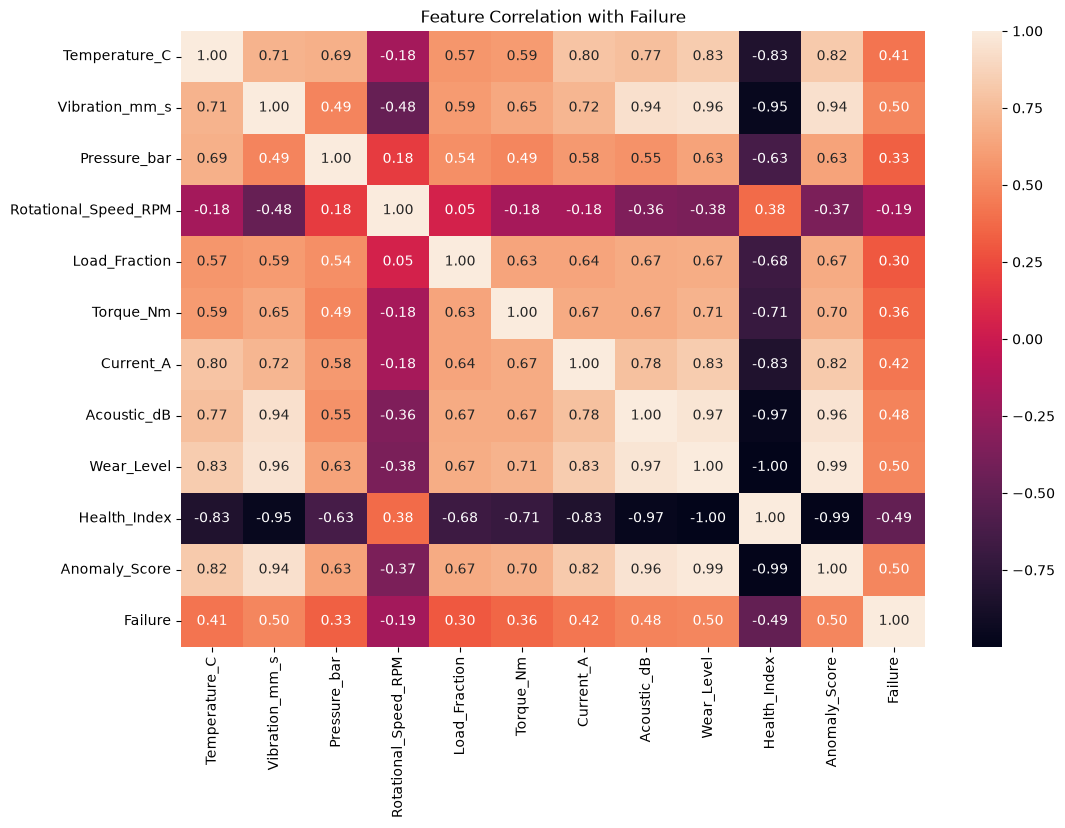

In [19]:
correlation_matrix = df[
    failure_features + ["Failure"]
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Feature Correlation with Failure")
plt.show()

In [20]:
baseline_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

baseline_classifier.fit(
    X_train_cls,
    y_train_cls
)

baseline_predictions = baseline_classifier.predict(
    X_val_cls
)

print(
    "Baseline Accuracy:",
    accuracy_score(
        y_val_cls,
        baseline_predictions
    )
)

Baseline Accuracy: 0.9377162629757786


In [21]:
baseline_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DummyRegressor(
                strategy="mean"
            )
        )
    ]
)

baseline_regressor.fit(
    X_train_reg,
    y_train_reg
)

baseline_reg_predictions = baseline_regressor.predict(
    X_val_reg
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val_reg,
        baseline_reg_predictions
    )
)

print("Baseline RMSE:", baseline_rmse)

Baseline RMSE: 84.9316441875012


In [22]:
rf_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

rf_classifier.fit(
    X_train_cls,
    y_train_cls
)

print("Random Forest classifier trained.")

Random Forest classifier trained.


In [23]:
def evaluate_classifier(model, X, y, model_name):
    
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions),
        "F1": f1_score(y, predictions),
        "ROC-AUC": roc_auc_score(y, probabilities)
    }

    return metrics

In [24]:
rf_results = evaluate_classifier(
    rf_classifier,
    X_val_cls,
    y_val_cls,
    "Random Forest"
)

display(
    pd.DataFrame([rf_results])
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.99308,0.9,1.0,0.947368,1.0


In [25]:
rf_predictions = rf_classifier.predict(X_val_cls)

print(
    classification_report(
        y_val_cls,
        rf_predictions
    )
)

              precision    recall  f1-score   support

           0       1.00      0.99      1.00       271
           1       0.90      1.00      0.95        18

    accuracy                           0.99       289
   macro avg       0.95      1.00      0.97       289
weighted avg       0.99      0.99      0.99       289



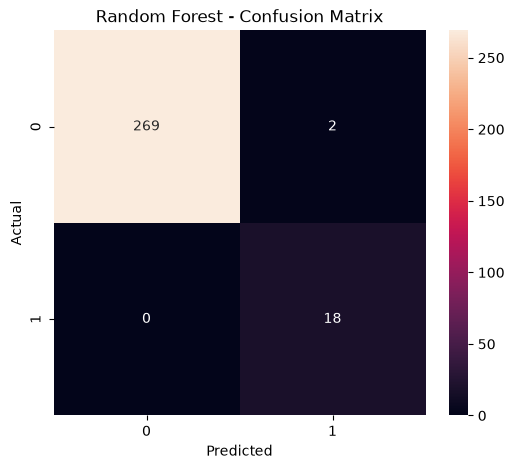

In [26]:
cm = confusion_matrix(
    y_val_cls,
    rf_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [27]:
rf_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_regressor.fit(
    X_train_reg,
    y_train_reg
)

print("Random Forest regressor trained.")

Random Forest regressor trained.


In [28]:
def evaluate_regressor(model, X, y, model_name):

    predictions = model.predict(X)

    mse = mean_squared_error(
        y,
        predictions
    )

    rmse = np.sqrt(mse)

    metrics = {
        "Model": model_name,
        "MAE": mean_absolute_error(
            y,
            predictions
        ),
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2_score(
            y,
            predictions
        )
    }

    return metrics

In [29]:
rf_reg_results = evaluate_regressor(
    rf_regressor,
    X_val_reg,
    y_val_reg,
    "Random Forest"
)

display(
    pd.DataFrame([rf_reg_results])
)

,Model,MAE,MSE,RMSE,R²
0,Random Forest,4.179227,33.611262,5.797522,0.99534


In [30]:
from xgboost import XGBClassifier, XGBRegressor

In [31]:
xgb_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                random_state=42,
                eval_metric="logloss"
            )
        )
    ]
)

xgb_classifier.fit(
    X_train_cls,
    y_train_cls
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Machine_ID','Machine_Type','Cycle',...,'Wear_Level','Health_Index', 'Anomaly_Score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [32]:
xgb_results = evaluate_classifier(
    xgb_classifier,
    X_val_cls,
    y_val_cls,
    "XGBoost"
)

display(
    pd.DataFrame(
        [rf_results, xgb_results]
    )
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.99308,0.900000,1.0,0.947368,1.0
1,XGBoost,0.99654,0.947368,1.0,0.972973,1.0


In [33]:
from lightgbm import LGBMClassifier, LGBMRegressor

In [34]:
lgb_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LGBMClassifier(
                n_estimators=300,
                learning_rate=0.05,
                random_state=42,
                verbosity=-1
            )
        )
    ]
)

lgb_classifier.fit(
    X_train_cls,
    y_train_cls
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Machine_ID','Machine_Type','Cycle',...,'Wear_Level','Health_Index', 'Anomaly_Score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [35]:
lgb_results = evaluate_classifier(
    lgb_classifier,
    X_val_cls,
    y_val_cls,
    "LightGBM"
)

classification_results = pd.DataFrame([
    rf_results,
    xgb_results,
    lgb_results
])

display(classification_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.99308,0.900000,1.0,0.947368,1.0
1,XGBoost,0.99654,0.947368,1.0,0.972973,1.0
2,LightGBM,0.99308,0.900000,1.0,0.947368,1.0


In [36]:
print("Failure distribution:")
print(y_val_cls.value_counts())

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_cls,
    xgb_classifier.predict(X_val_cls)
))

Failure distribution:
Failure
0    271
1     18
Name: count, dtype: int64

Confusion Matrix:
[[270   1]
 [  0  18]]


In [37]:
print("Classification report:")
print(
    classification_report(
        y_val_cls,
        xgb_classifier.predict(X_val_cls)
    )
)

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       271
           1       0.95      1.00      0.97        18

    accuracy                           1.00       289
   macro avg       0.97      1.00      0.99       289
weighted avg       1.00      1.00      1.00       289



### Experiment - Training other model due to high accuracy and will validate since there could be wrong feature selection

In [38]:
# ============================================
# EXPERIMENT 2
# Clean Feature Set
# ============================================

selected_features = [
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Machine_Type"
]

X_clean = df[selected_features].copy()
y_clean = df["Failure"].copy()

print("Selected Features:")
print(selected_features)

print("\nX shape:", X_clean.shape)
print("y shape:", y_clean.shape)

display(X_clean.head())

Selected Features:
['Cycle', 'Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM', 'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB', 'Wear_Level', 'Machine_Type']

X shape: (1930, 11)
y shape: (1930,)


,Cycle,Temperature_C,Vibration_mm_s,Pressure_bar,Rotational_Speed_RPM,Load_Fraction,Torque_Nm,Current_A,Acoustic_dB,Wear_Level,Machine_Type
0,1,68.987,0.2351,2.117,1518.64,0.6513,46.734,9.213,56.022,0.0000,CNC_Mill
1,2,69.431,0.1894,2.126,1517.67,0.5961,46.603,9.480,55.789,0.0000,CNC_Mill
2,3,68.779,0.2385,2.119,1520.83,0.6336,46.313,9.612,54.954,0.0022,CNC_Mill
3,4,68.926,0.2047,2.110,1531.69,0.6898,48.403,9.907,54.567,0.0000,CNC_Mill
4,5,68.704,0.2086,2.079,1516.70,0.5900,48.188,9.080,54.424,0.0006,CNC_Mill


In [39]:
# ============================================
# EXPERIMENT 2
# Train / Validation / Test Split
# ============================================

X_train_clean, X_temp_clean, y_train_clean, y_temp_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.30,
    random_state=42,
    stratify=y_clean
)

X_val_clean, X_test_clean, y_val_clean, y_test_clean = train_test_split(
    X_temp_clean,
    y_temp_clean,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_clean
)

print("Train shape:", X_train_clean.shape)
print("Validation shape:", X_val_clean.shape)
print("Test shape:", X_test_clean.shape)

print("\nTarget distribution:")

print("\nTraining:")
print(y_train_clean.value_counts())

print("\nValidation:")
print(y_val_clean.value_counts())

print("\nTesting:")
print(y_test_clean.value_counts())

Train shape: (1351, 11)
Validation shape: (289, 11)
Test shape: (290, 11)

Target distribution:

Training:
Failure
0    1266
1      85
Name: count, dtype: int64

Validation:
Failure
0    271
1     18
Name: count, dtype: int64

Testing:
Failure
0    271
1     19
Name: count, dtype: int64


In [40]:
# ============================================
# EXPERIMENT 2
# Step 4: Preprocessing
# ============================================

categorical_features_clean = X_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features_clean = X_clean.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features_clean)

print("\nNumerical Features:")
print(numerical_features_clean)

Categorical Features:
['Machine_Type']

Numerical Features:
['Cycle', 'Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM', 'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB', 'Wear_Level']


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_clean = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features_clean
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_clean
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [42]:
# ============================================
# STEP 5: BASELINE MODEL
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier

baseline_clean = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_clean
        ),
        (
            "model",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

baseline_clean.fit(
    X_train_clean,
    y_train_clean
)

baseline_predictions_clean = baseline_clean.predict(
    X_val_clean
)

baseline_accuracy_clean = accuracy_score(
    y_val_clean,
    baseline_predictions_clean
)

print(
    f"Baseline Validation Accuracy: "
    f"{baseline_accuracy_clean:.4f}"
)

Baseline Validation Accuracy: 0.9377


In [43]:
# ============================================
# STEP 6A: RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestClassifier

rf_clean = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_clean
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

rf_clean.fit(
    X_train_clean,
    y_train_clean
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [44]:
# ============================================
# STEP 6B: XGBOOST
# ============================================

from xgboost import XGBClassifier

xgb_clean = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_clean
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                random_state=42,
                eval_metric="logloss"
            )
        )
    ]
)

xgb_clean.fit(
    X_train_clean,
    y_train_clean
)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [45]:
# ============================================
# STEP 6C: LIGHTGBM
# ============================================

from lightgbm import LGBMClassifier

lgb_clean = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_clean
        ),
        (
            "model",
            LGBMClassifier(
                n_estimators=300,
                learning_rate=0.05,
                random_state=42,
                verbosity=-1
            )
        )
    ]
)

lgb_clean.fit(
    X_train_clean,
    y_train_clean
)

print("LightGBM trained successfully.")

LightGBM trained successfully.


In [46]:
# ============================================
# STEP 7: MODEL EVALUATION
# ============================================

def evaluate_classifier_clean(
    model,
    X,
    y,
    model_name
):
    
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y,
            predictions
        ),
        "Precision": precision_score(
            y,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y,
            predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y,
            probabilities
        )
    }

In [47]:
# ============================================
# MODEL COMPARISON
# ============================================

rf_clean_results = evaluate_classifier_clean(
    rf_clean,
    X_val_clean,
    y_val_clean,
    "Random Forest"
)

xgb_clean_results = evaluate_classifier_clean(
    xgb_clean,
    X_val_clean,
    y_val_clean,
    "XGBoost"
)

lgb_clean_results = evaluate_classifier_clean(
    lgb_clean,
    X_val_clean,
    y_val_clean,
    "LightGBM"
)

clean_results = pd.DataFrame([
    rf_clean_results,
    xgb_clean_results,
    lgb_clean_results
])

display(
    clean_results.round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.9931,0.9000,1.0,0.9474,0.9996
1,XGBoost,0.9965,0.9474,1.0,0.9730,1.0000
2,LightGBM,0.9931,0.9000,1.0,0.9474,1.0000


In [48]:
# ============================================
# CONFUSION MATRICES
# ============================================

models_clean = {
    "Random Forest": rf_clean,
    "XGBoost": xgb_clean,
    "LightGBM": lgb_clean
}

for name, model in models_clean.items():

    predictions = model.predict(X_val_clean)

    cm = confusion_matrix(
        y_val_clean,
        predictions
    )

    print(f"\n{name}")
    print(cm)


Random Forest
[[269   2]
 [  0  18]]

XGBoost
[[270   1]
 [  0  18]]

LightGBM
[[269   2]
 [  0  18]]


In [49]:
# ============================================
# CLASSIFICATION REPORTS
# ============================================

for name, model in models_clean.items():

    predictions = model.predict(
        X_val_clean
    )

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_val_clean,
            predictions,
            zero_division=0
        )
    )


Random Forest
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       271
           1       0.90      1.00      0.95        18

    accuracy                           0.99       289
   macro avg       0.95      1.00      0.97       289
weighted avg       0.99      0.99      0.99       289


XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       271
           1       0.95      1.00      0.97        18

    accuracy                           1.00       289
   macro avg       0.97      1.00      0.99       289
weighted avg       1.00      1.00      1.00       289


LightGBM
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       271
           1       0.90      1.00      0.95        18

    accuracy                           0.99       289
   macro avg       0.95      1.00      0.97       289
weighted avg       0.99      0.99      0

In [50]:
# ============================================
# STEP 8: FEATURE IMPORTANCE
# ============================================

feature_names_clean = (
    rf_clean
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print(
    "Number of transformed features:",
    len(feature_names_clean)
)

Number of transformed features: 17


In [51]:
rf_importance = (
    rf_clean
    .named_steps["model"]
    .feature_importances_
)

rf_feature_importance = pd.DataFrame({
    "Feature": feature_names_clean,
    "Importance": rf_importance
})

rf_feature_importance = (
    rf_feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

display(
    rf_feature_importance.head(15)
)

,Feature,Importance
9,num__Wear_Level,0.368332
8,num__Acoustic_dB,0.176601
2,num__Vibration_mm_s,0.163507
0,num__Cycle,0.116403
1,num__Temperature_C,0.080271
7,num__Current_A,0.041104
6,num__Torque_Nm,0.016657
3,num__Pressure_bar,0.016405
5,num__Load_Fraction,0.011567
4,num__Rotational_Speed_RPM,0.006423


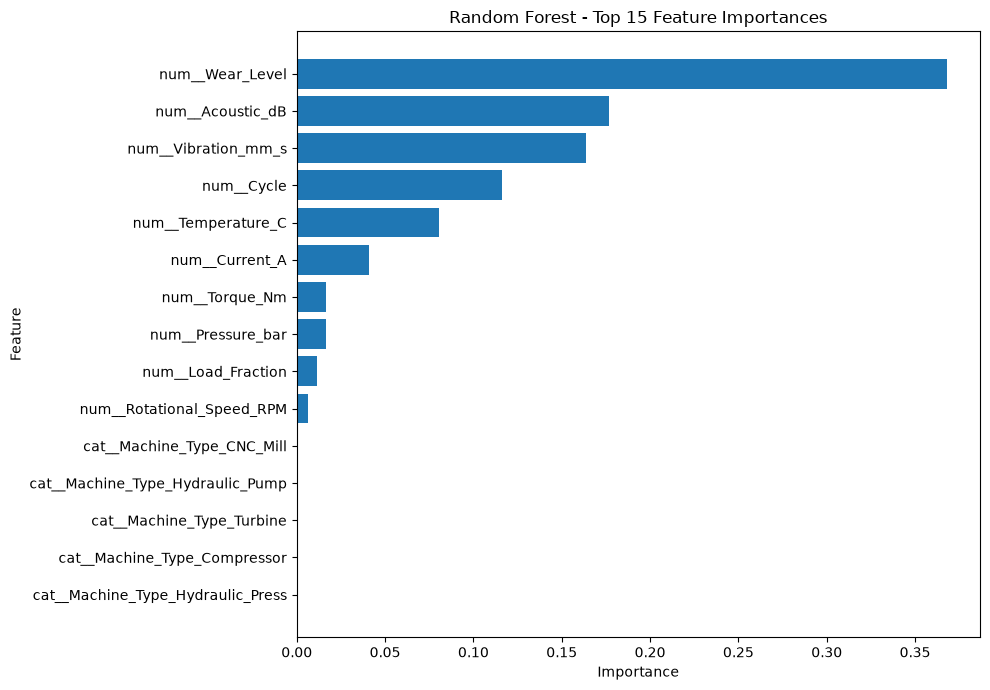

In [52]:
# ============================================
# FEATURE IMPORTANCE VISUALIZATION
# ============================================

top_features = (
    rf_feature_importance
    .head(15)
    .sort_values("Importance")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    "Random Forest - Top 15 Feature Importances"
)

plt.tight_layout()
plt.show()

In [53]:
# ============================================
# EXPERIMENT 1 VS EXPERIMENT 2
# ============================================

experiment_1_results = classification_results.copy()

experiment_1_results["Experiment"] = (
    "Experiment 1 - All Features"
)

clean_results_comparison = clean_results.copy()

clean_results_comparison["Experiment"] = (
    "Experiment 2 - Clean Features"
)

comparison = pd.concat(
    [
        experiment_1_results,
        clean_results_comparison
    ],
    ignore_index=True
)

comparison = comparison[
    [
        "Experiment",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
]

display(
    comparison.round(4)
)

,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Experiment 1 - All Features,Random Forest,0.9931,0.9000,1.0,0.9474,1.0000
1,Experiment 1 - All Features,XGBoost,0.9965,0.9474,1.0,0.9730,1.0000
2,Experiment 1 - All Features,LightGBM,0.9931,0.9000,1.0,0.9474,1.0000
3,Experiment 2 - Clean Features,Random Forest,0.9931,0.9000,1.0,0.9474,0.9996
4,Experiment 2 - Clean Features,XGBoost,0.9965,0.9474,1.0,0.9730,1.0000
5,Experiment 2 - Clean Features,LightGBM,0.9931,0.9000,1.0,0.9474,1.0000


In [54]:
# ============================================
# STEP 9: MODEL SELECTION
# ============================================

clean_results_sorted = clean_results.sort_values(
    by=["F1", "Recall", "ROC-AUC"],
    ascending=False
)

display(clean_results_sorted.round(4))

best_model_name = clean_results_sorted.iloc[0]["Model"]

print("Best model based on validation metrics:")
print(best_model_name)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,XGBoost,0.9965,0.9474,1.0,0.9730,1.0000
2,LightGBM,0.9931,0.9000,1.0,0.9474,1.0000
0,Random Forest,0.9931,0.9000,1.0,0.9474,0.9996


Best model based on validation metrics:
XGBoost


In [55]:
# ============================================
# SELECT BEST MODEL OBJECT
# ============================================

if best_model_name == "Random Forest":
    final_classifier = rf_clean

elif best_model_name == "XGBoost":
    final_classifier = xgb_clean

elif best_model_name == "LightGBM":
    final_classifier = lgb_clean

else:
    raise ValueError("Unknown model selected.")

print("Selected final classifier:", best_model_name)

Selected final classifier: XGBoost


In [56]:
# ============================================
# STEP 10: FINAL TEST EVALUATION
# ============================================

final_test_predictions = final_classifier.predict(
    X_test_clean
)

final_test_probabilities = final_classifier.predict_proba(
    X_test_clean
)[:, 1]

final_test_metrics = {
    "Model": best_model_name,
    "Accuracy": accuracy_score(
        y_test_clean,
        final_test_predictions
    ),
    "Precision": precision_score(
        y_test_clean,
        final_test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test_clean,
        final_test_predictions,
        zero_division=0
    ),
    "F1": f1_score(
        y_test_clean,
        final_test_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_clean,
        final_test_probabilities
    )
}

final_test_results = pd.DataFrame(
    [final_test_metrics]
)

display(final_test_results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.9862,0.9412,0.8421,0.8889,0.9992


Final Test Confusion Matrix:
[[270   1]
 [  3  16]]


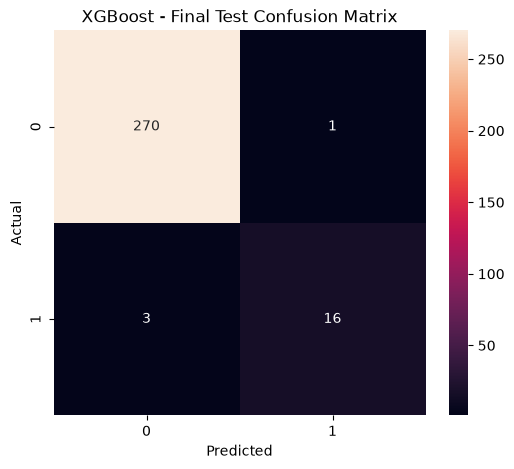

In [57]:
# ============================================
# FINAL TEST CONFUSION MATRIX
# ============================================

final_cm = confusion_matrix(
    y_test_clean,
    final_test_predictions
)

print("Final Test Confusion Matrix:")
print(final_cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d"
)

plt.title(
    f"{best_model_name} - Final Test Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [58]:
# ============================================
# FINAL TEST CLASSIFICATION REPORT
# ============================================

print(
    classification_report(
        y_test_clean,
        final_test_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       271
           1       0.94      0.84      0.89        19

    accuracy                           0.99       290
   macro avg       0.97      0.92      0.94       290
weighted avg       0.99      0.99      0.99       290



In [59]:
# ============================================
# STEP 11: SAVE FINAL FAILURE MODEL
# ============================================

import joblib
import os

os.makedirs(
    "../models",
    exist_ok=True
)

model_path = "../models/failure_prediction_model.pkl"

joblib.dump(
    final_classifier,
    model_path
)

print("Final model saved successfully!")
print("Model:", best_model_name)
print("Path:", model_path)

Final model saved successfully!
Model: XGBoost
Path: ../models/failure_prediction_model.pkl


In [60]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nXGBoost:")
%pip show xgboost

Python executable:
/home/labuser/Desktop/Project/3203141-Capstone_Proj/smart-twin/bin/python

Python version:
3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:09:02) [GCC 11.2.0]

XGBoost:
Name: xgboost
Version: 3.4.0
Summary: XGBoost Python Package
Home-page: 
Author: 
Author-email: Hyunsu Cho <chohyu01@cs.washington.edu>, Jiaming Yuan <jm.yuan@outlook.com>
License-Expression: Apache-2.0
Location: /home/labuser/Desktop/Project/3203141-Capstone_Proj/smart-twin/lib/python3.13/site-packages
Requires: numpy, nvidia-nccl-cu13, scipy
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [62]:
import sys
import numpy
import pandas
import scipy
import sklearn
import joblib
import xgboost
import lightgbm
import matplotlib
import seaborn

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", seaborn.__version__)

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:09:02) [GCC 11.2.0]
NumPy: 2.5.2
Pandas: 3.0.5
SciPy: 1.18.0
Scikit-learn: 1.9.0
Joblib: 1.5.3
XGBoost: 3.4.0
LightGBM: 4.7.0
Matplotlib: 3.11.1
Seaborn: 0.13.2
